# Task 4: Email Spam Detection with Machine Learning

## Introduction

Spam messages are unwanted or unsolicited messages that may contain advertisements, misleading information, fraudulent offers, or harmful links. Identifying spam messages automatically is important for protecting users from unwanted communication and potential online threats.

The objective of this project is to develop a Machine Learning classification model using Natural Language Processing (NLP) to distinguish between spam and legitimate (ham) messages.

This project uses the SMS Spam Collection dataset and applies text preprocessing techniques such as lowercase conversion, punctuation removal, and stopword removal. TF-IDF (Term Frequency–Inverse Document Frequency) is used to convert text messages into numerical features.

Two classification algorithms, Multinomial Naive Bayes and Logistic Regression, are trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The best-performing model is then used to classify new sample messages as spam or ham.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk wordcloud

  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 1.4 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 1.9 MB/s eta 0:00:01
   ------------------------------ --------- 1.3/1.7 MB 2.0 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 1.8 MB/s eta 0:00:00
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import nltk
from nltk.corpus import stopwords

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# WordCloud
from wordcloud import WordCloud

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load the SMS spam dataset
df = pd.read_csv("spam.csv", encoding="latin-1")

# Display the first five rows
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 5)

Column Names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 217.8 KB

Missing Values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


In [5]:
# Keep only the required columns
df = df[["v1", "v2"]]

# Rename columns for clarity
df.columns = ["label", "message"]

# Remove duplicate messages
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Display the cleaned dataset shape
print("Cleaned Dataset Shape:", df.shape)

# Display first five rows
df.head()

Cleaned Dataset Shape: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Message Counts:
label
ham     4516
spam     653
Name: count, dtype: int64

Message Percentages:
label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


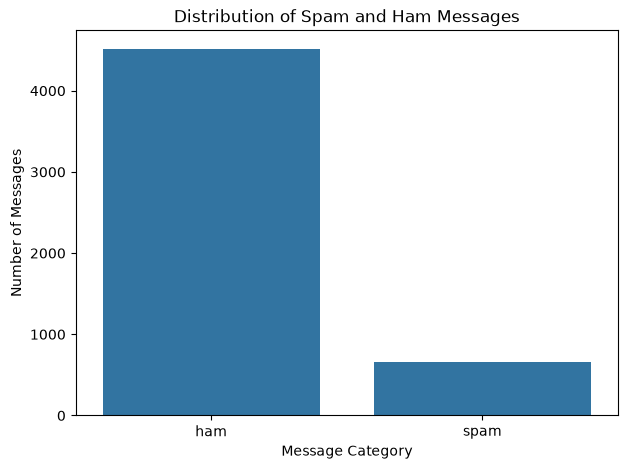

In [6]:
# Count spam and ham messages
label_counts = df["label"].value_counts()

print("Message Counts:")
print(label_counts)

# Calculate percentages
label_percentages = df["label"].value_counts(normalize=True) * 100

print("\nMessage Percentages:")
print(label_percentages.round(2))

# Visualize class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.show()

In [7]:
# Download English stopwords
nltk.download("stopwords")

# Load the English stopwords list
stop_words = set(stopwords.words("english"))

print("Stopwords downloaded successfully!")
print("Total stopwords:", len(stop_words))

[nltk_data] Downloading package stopwords to C:\Users\Ishwari
[nltk_data]     Pednekar\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


Stopwords downloaded successfully!
Total stopwords: 198


In [8]:
# Function to clean text messages
def preprocess_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # Join cleaned words
    text = " ".join(words)

    return text


# Apply preprocessing to all messages
df["cleaned_message"] = df["message"].apply(preprocess_text)

# Display original and cleaned messages
df[["message", "cleaned_message"]].head()

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


## TF-IDF (Term Frequency–Inverse Document Frequency)

TF-IDF is a text feature extraction technique used in Natural Language Processing (NLP) to convert text messages into numerical values that a machine learning model can understand.

It measures how important a word is in a particular message compared to the entire collection of messages.

- **Term Frequency (TF):** Measures how frequently a word appears in a message.
- **Inverse Document Frequency (IDF):** Measures how rare or common a word is across all messages. Rare words generally receive higher importance.

TF-IDF gives higher importance to words that are frequent in a particular message but less common across the overall dataset.

In this project, TF-IDF will convert the cleaned messages into numerical features for spam and ham classification.

In [9]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert cleaned messages into numerical features
X = tfidf.fit_transform(df["cleaned_message"])

# Target variable (spam or ham)
y = df["label"]

# Display the shape of the TF-IDF matrix
print("TF-IDF Matrix Shape:", X.shape)

# Display number of features
print("Number of TF-IDF Features:", len(tfidf.get_feature_names_out()))


TF-IDF Matrix Shape: (5169, 5000)
Number of TF-IDF Features: 5000


In [10]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data Shape: (4135, 5000)
Testing Data Shape: (1034, 5000)

Training Labels: (4135,)
Testing Labels: (1034,)


In [11]:
# Create Multinomial Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train, y_train)

# Predict test data
y_pred_nb = nb_model.predict(X_test)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [12]:
# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Predict test data
y_pred_lr = lr_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# Function to evaluate a classification model
def evaluate_model(y_true, y_pred, model_name):

    print("\n", model_name)
    print("-" * 40)

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, pos_label="spam"), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, pos_label="spam"), 4))
    print("F1-Score :", round(f1_score(y_true, y_pred, pos_label="spam"), 4))


# Evaluate Naive Bayes
evaluate_model(y_test, y_pred_nb, "Multinomial Naive Bayes")

# Evaluate Logistic Regression
evaluate_model(y_test, y_pred_lr, "Logistic Regression")


 Multinomial Naive Bayes
----------------------------------------
Accuracy : 0.9671
Precision: 0.9899
Recall   : 0.7481
F1-Score : 0.8522

 Logistic Regression
----------------------------------------
Accuracy : 0.9468
Precision: 0.975
Recall   : 0.5954
F1-Score : 0.7393


## Why Is Recall Important in Spam Detection?

Recall is an important evaluation metric in spam detection because it measures how many actual spam messages are correctly identified by the model.

A low recall means that many spam messages are incorrectly classified as legitimate messages (ham). These missed spam messages may contain unwanted advertisements, scams, or potentially harmful links.

A higher recall helps the model detect more spam messages and reduces the number of spam messages that reach the user's inbox.

However, precision is also important because legitimate messages should not be incorrectly marked as spam.

Therefore, a good spam detection model should aim for a balance between high recall and high precision.

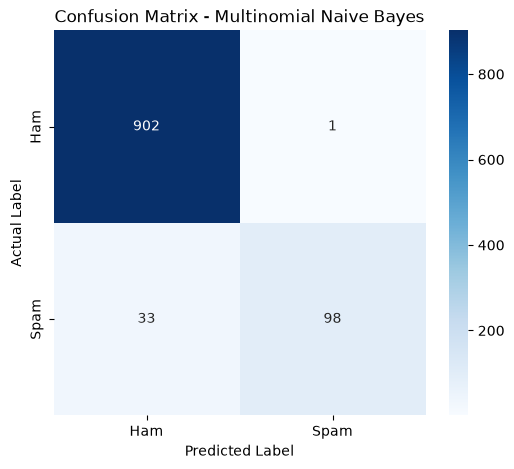

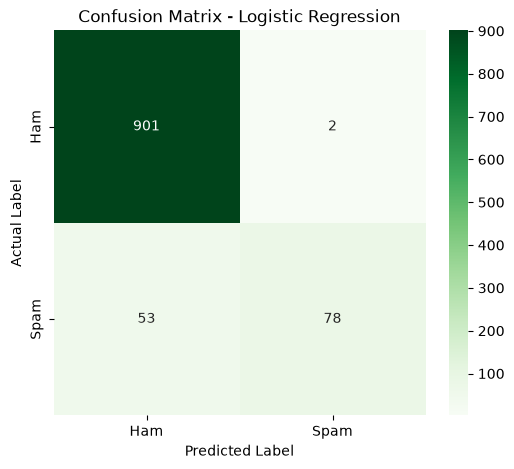

In [14]:
# Create confusion matrices
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=["ham", "spam"])
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=["ham", "spam"])

# Plot Naive Bayes confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# Plot Logistic Regression confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

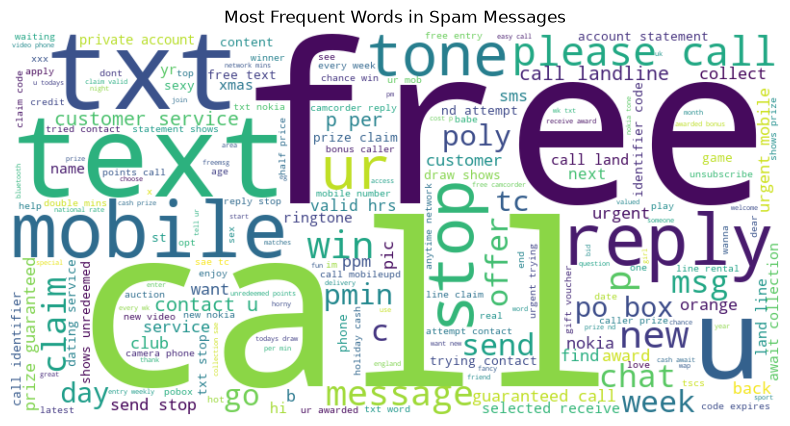

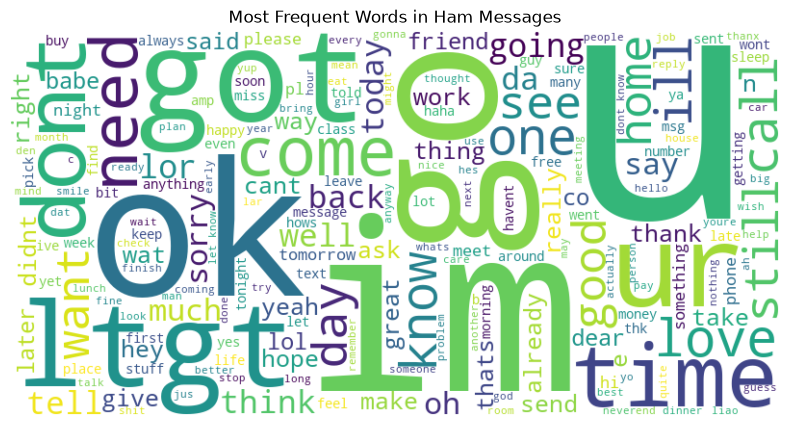

In [15]:
# Separate spam and ham messages
spam_text = " ".join(
    df[df["label"] == "spam"]["cleaned_message"]
)

ham_text = " ".join(
    df[df["label"] == "ham"]["cleaned_message"]
)

# Generate Spam WordCloud
spam_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(spam_text)

plt.figure(figsize=(10, 5))
plt.imshow(spam_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Spam Messages")
plt.show()


# Generate Ham WordCloud
ham_wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(ham_text)

plt.figure(figsize=(10, 5))
plt.imshow(ham_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Ham Messages")
plt.show()

In [16]:
# Create sample messages
sample_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! Claim your free cash reward now!",
    "I will call you when I reach home."
]

# Preprocess the sample messages
cleaned_samples = [preprocess_text(msg) for msg in sample_messages]

# Convert messages using the trained TF-IDF vectorizer
sample_features = tfidf.transform(cleaned_samples)

# Predict message categories
predictions = nb_model.predict(sample_features)

# Display predictions
for message, prediction in zip(sample_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 60)

Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
------------------------------------------------------------
Message: Hey, are we meeting for lunch today?
Prediction: HAM
------------------------------------------------------------
Message: URGENT! Claim your free cash reward now!
Prediction: SPAM
------------------------------------------------------------
Message: I will call you when I reach home.
Prediction: HAM
------------------------------------------------------------


## Observations

1. The original dataset contained 5,572 messages and 5 columns.
2. After removing duplicate records and unnecessary columns, 5,169 messages remained.
3. Text preprocessing included lowercase conversion, punctuation and number removal, and stopword removal.
4. TF-IDF converted the cleaned messages into 5,000 numerical features.
5. Two classification models were trained: Multinomial Naive Bayes and Logistic Regression.
6. Multinomial Naive Bayes performed better across all four evaluation metrics.
7. The sample messages were successfully classified as spam or ham.

## Model Evaluation Results

| Evaluation Metric | Multinomial Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 0.9671 | 0.9468 |
| Precision | 0.9899 | 0.9750 |
| Recall | 0.7481 | 0.5954 |
| F1-score | 0.8522 | 0.7393 |

## Conclusion

This project demonstrates how Natural Language Processing and Machine Learning can be used to identify spam and legitimate messages.

Among the two trained models, Multinomial Naive Bayes achieved the best performance, with an accuracy of 96.71% and an F1-score of 85.22%.

The model successfully classified sample messages into spam and ham categories. Recall is particularly important in spam detection because it helps identify more actual spam messages and reduces the number of unwanted messages that go undetected.

Overall, this project provides a practical understanding of text preprocessing, TF-IDF feature extraction, classification algorithms, and model evaluation.